# ROI_processing

In [1]:
import spatialdata_io
import spatialdata as sd
import troutpy
import scanpy as sc
from spatialdata import SpatialData
import matplotlib.pyplot as plt
from spatialdata.transformations import get_transformation
import matplotlib.patches as patches
import os
import numpy as np
import sys
import seaborn as sns

import hotspot

/home/sergio/.local/lib/python3.10/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(
/home/sergio/.local/lib/python3.10/site-packages/numba/core/decorators.py:246: RuntimeWarning: nopython is set for njit and is ignored
  warnings.warn('nopython is set for njit and is ignored', RuntimeWarning)
/home/sergio/.local/lib/python3.10/site-packages/anndata/utils.py:429: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_text instead.
  warnings.warn(msg, FutureWarning)
/home/sergio/.local/lib/python3.10/site-packages/anndata/utils.py:429: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_text instead.
  warnings.warn(msg, FutureWarning)


In [3]:
# Technology 1: Xenium
sdata = sd.read_zarr("/media/sergio/Meninges/troutpy/rois/xenium_msbrain_5k/data_processed.zarr")
results = sdata["xrna_metadata"].var

In [ ]:
adata = sdata["table"]
hs = hotspot.Hotspot(adata, layer_key="raw", model="danb", latent_obsm_key="X_pca", umi_counts_obs_key="total_counts")

hs.create_knn_graph(weighted_graph=False, n_neighbors=10)
hs_results = hs.compute_autocorrelations()
hs_genes = hs_results.loc[hs_results.FDR < 0.001].index  # Select genes
local_correlations = hs.compute_local_correlations(hs_genes, jobs=4)  # jobs for parallelization

100%|██████████| 4993/4993 [01:39<00:00, 50.23it/s]


Computing pair-wise local correlation on 3995 features...


100%|██████████| 7978015/7978015 [37:35<00:00, 3536.67it/s]


Computing scores for 155 modules...


100%|██████████| 155/155 [00:20<00:00,  7.54it/s]


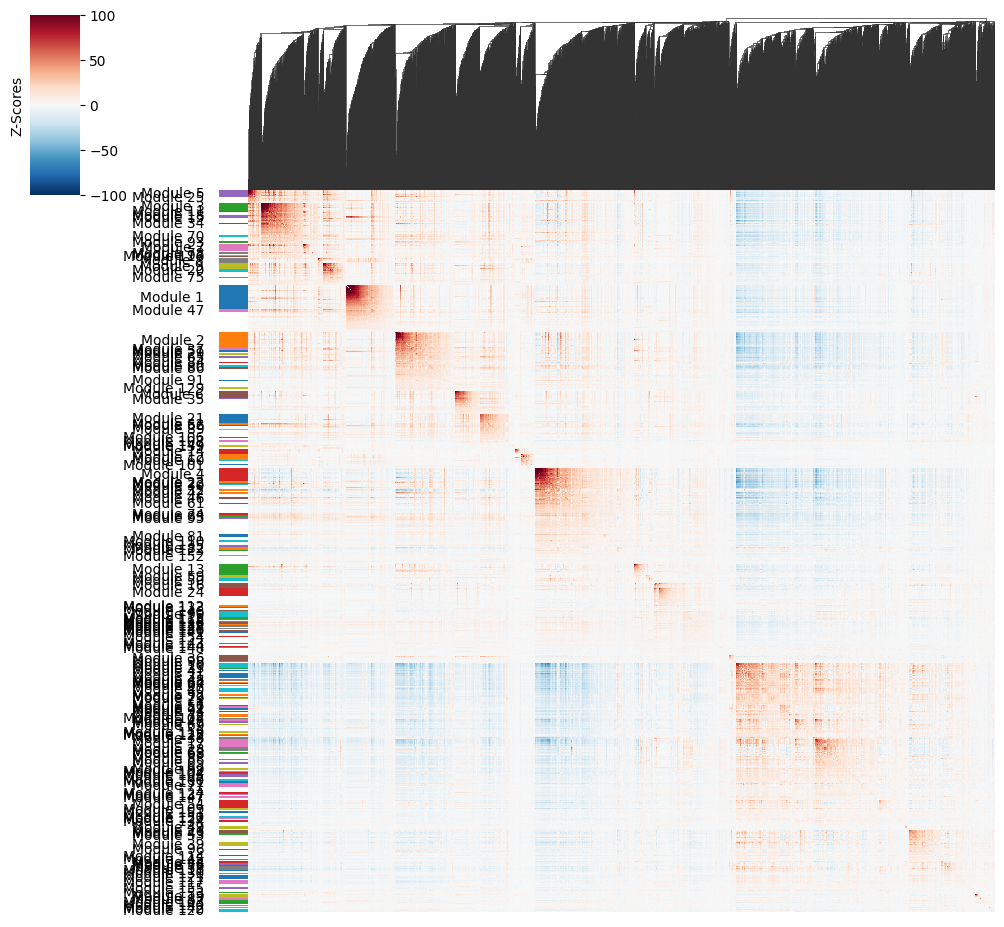

In [5]:
hs.plot_local_correlations(vmax=100, vmin=-100)

In [10]:
# calculate modules
modules = hs.create_modules(min_gene_threshold=30, core_only=True, fdr_threshold=0.0005)
module_scores = hs.calculate_module_scores()

Computing scores for 26 modules...


100%|██████████| 26/26 [00:07<00:00,  3.37it/s]


In [ ]:
adata_scores = sc.AnnData(module_scores, obs=adata.obs)
adata_scores.obsm["X_umap"] = adata.obsm["X_umap"]
adata_scores.obsm["X_pca"] = adata.obsm["X_pca"]
sc.pl.umap(adata, color="leiden")
sc.pl.umap(adata_scores, color=adata_scores.var.index, vmax="p99")

In [12]:
dictmod = dict(zip(modules.index, modules.values))
results["module"] = results.index.map(dictmod)

In [13]:
import matplotlib.pyplot as plt


def annotate_top_bottom(
    df, metric1, metric2, n=5, label_col=None, figsize=(8, 6), scatter_kwargs=None, annotate_kwargs=None, title_tag=""
):
    """
    Scatter-plot df[metric1] vs df[metric2] and annotate the top/bottom n points
    along each axis.

    Parameters
    ----------
    df : pandas.DataFrame
        The data.
    metric1 : str
        Column name for the x-axis metric.
    metric2 : str
        Column name for the y-axis metric.
    n : int, optional (default=5)
        Number of top and bottom points to label per metric.
    label_col : str or None, optional (default=None)
        Column name containing the labels. If None, uses df.index.
    figsize : tuple, optional (default=(8, 6))
        Figure size.
    scatter_kwargs : dict or None
        Extra kwargs passed to plt.scatter().
    annotate_kwargs : dict or None
        Extra kwargs passed to plt.annotate().
    Title tag: str, optional (default='')

    Returns
    -------
    fig, ax : matplotlib.figure.Figure, matplotlib.axes.Axes
        The figure and axes objects.
    """
    # Prepare labels
    df_plot = df.copy()
    if label_col is None:
        df_plot["__idx_label"] = df_plot.index.astype(str)
        label_col = "__idx_label"

    # Plot
    fig, ax = plt.subplots(figsize=figsize)
    sc_kwargs = {} if scatter_kwargs is None else scatter_kwargs
    ax.scatter(df_plot[metric1], df_plot[metric2], **sc_kwargs)
    ax.set_xlabel(metric1)
    ax.set_ylabel(metric2)
    ax.set_title(f"{title_tag}: {metric1} vs {metric2}")

    # Find indices to annotate
    top1 = df_plot.nlargest(n, metric1).index
    bot1 = df_plot.nsmallest(n, metric1).index
    top2 = df_plot.nlargest(n, metric2).index
    bot2 = df_plot.nsmallest(n, metric2).index
    to_annotate = set(top1) | set(bot1) | set(top2) | set(bot2)

    # Annotate
    ann_kwargs = dict(xytext=(5, 5), textcoords="offset points", ha="left", va="bottom", fontsize=8, alpha=0.8)
    if annotate_kwargs:
        ann_kwargs.update(annotate_kwargs)

    for idx in to_annotate:
        x = df_plot.loc[idx, metric1]
        y = df_plot.loc[idx, metric2]
        label = df_plot.loc[idx, label_col]
        ax.annotate(label, xy=(x, y), **ann_kwargs)

    fig.tight_layout()
    return fig, ax

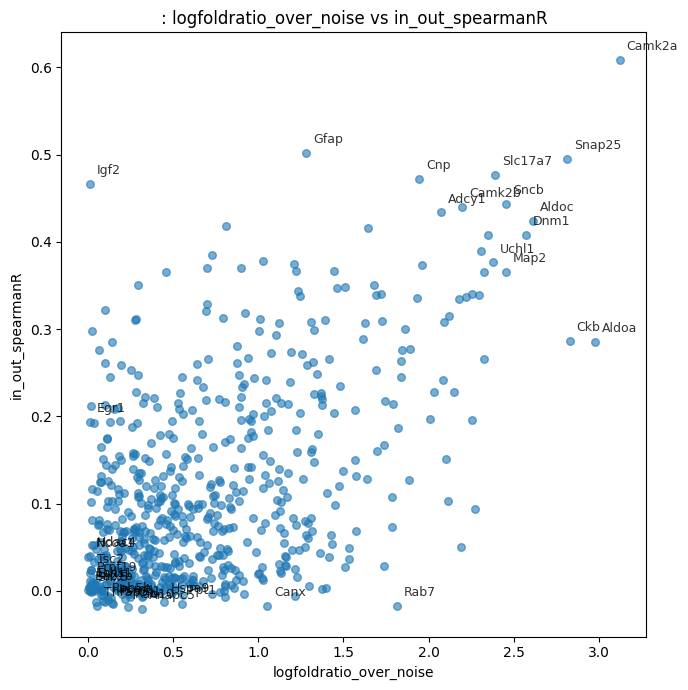

In [38]:
results2 = results[results["logfoldratio_over_noise"] > 0]
fig, ax = annotate_top_bottom(
    df=results2,
    metric1="logfoldratio_over_noise",
    metric2="in_out_spearmanR",
    n=10,
    scatter_kwargs={"alpha": 0.6, "s": 30},
    annotate_kwargs={"fontsize": 9, "color": "black"},
    figsize=(7, 7),
)
plt.show()

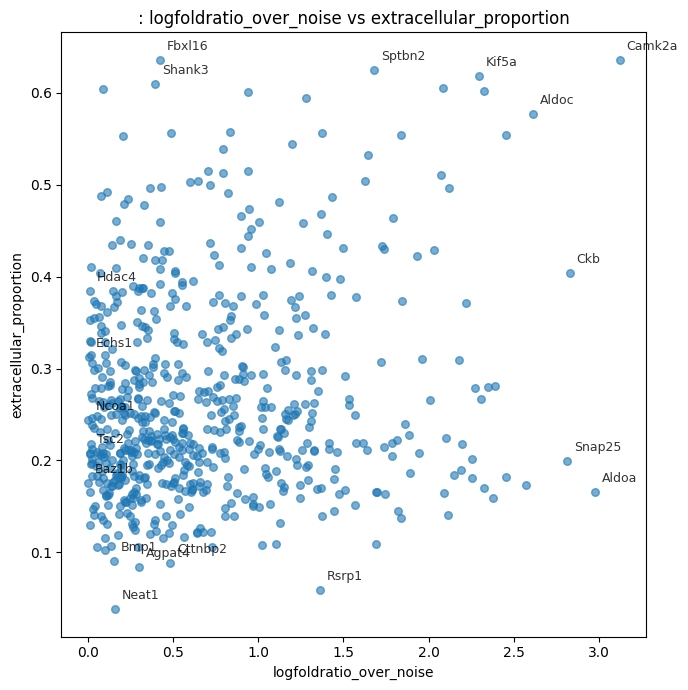

In [18]:
fig, ax = annotate_top_bottom(
    df=results2,
    metric1="logfoldratio_over_noise",
    metric2="extracellular_proportion",
    n=5,
    scatter_kwargs={"alpha": 0.6, "s": 30},
    annotate_kwargs={"fontsize": 9, "color": "black"},
    figsize=(7, 7),
)
plt.show()

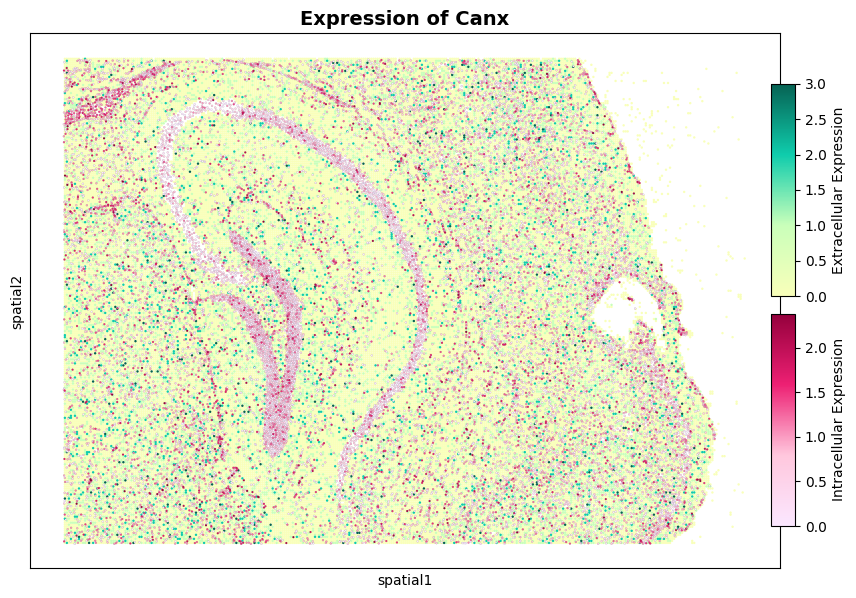

In [30]:
# spatial maps-in out
g2 = "Canx"
troutpy.pl.spatial_inout_expression(sdata, g2, spot_size_cells=10)

In [ ]:
for g, i in results.groupby("module"):
    if g > -1:
        print(g)
        # Suppose `results` is your DataFrame and you have a column 'gene' with names:
        fig, ax = annotate_top_bottom(
            df=i,
            metric1="logfoldratio_over_noise",
            metric2="extracellular_proportion",
            n=5,
            scatter_kwargs={"alpha": 0.6, "s": 30},
            annotate_kwargs={"fontsize": 9, "color": "black"},
            title_tag=g,
            figsize=(3, 3),
        )
        plt.show()

1.0


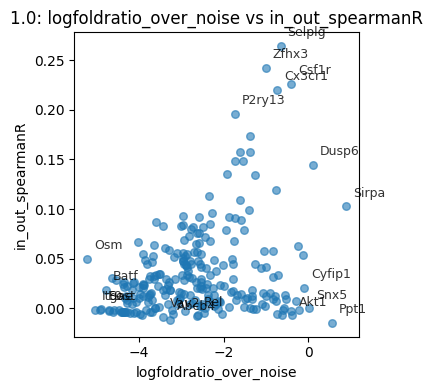

2.0


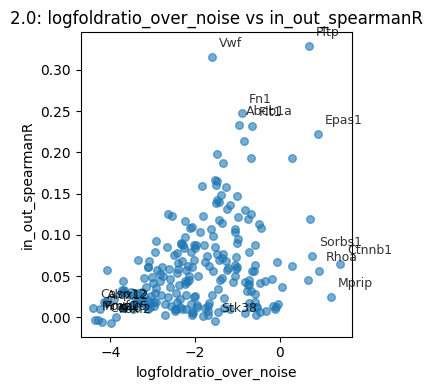

3.0


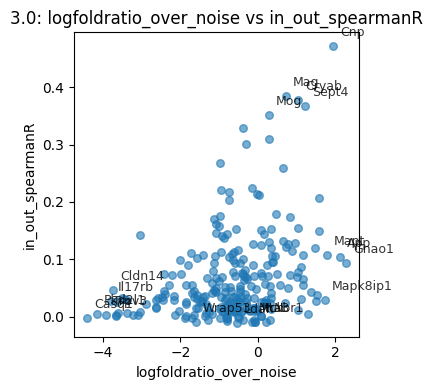

4.0


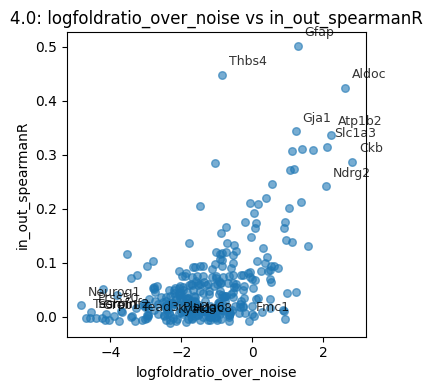

5.0


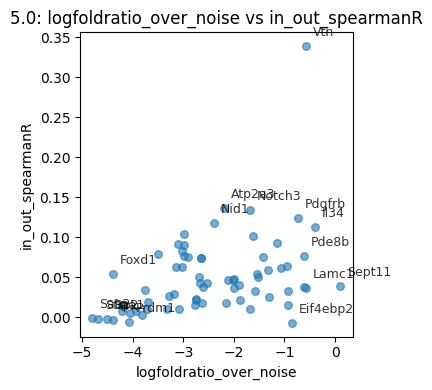

6.0


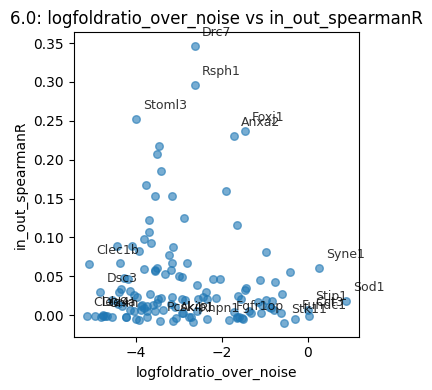

7.0


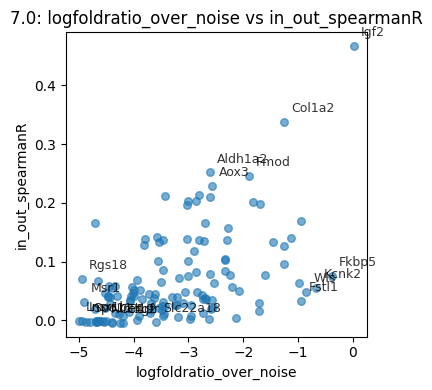

8.0


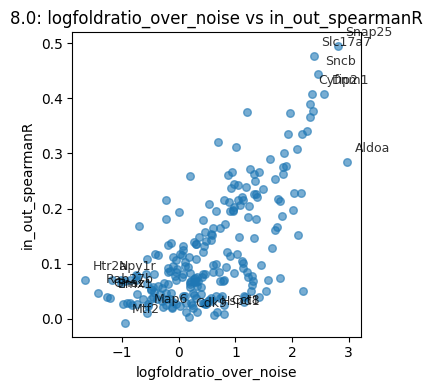

9.0


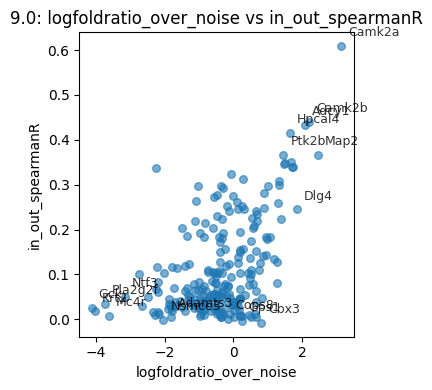

10.0


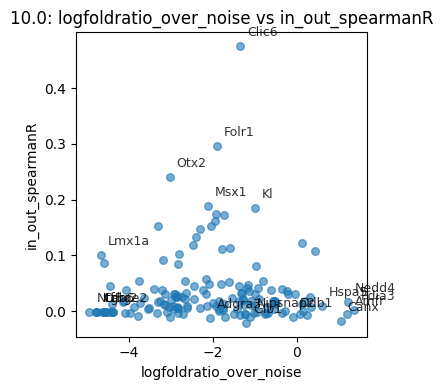

11.0


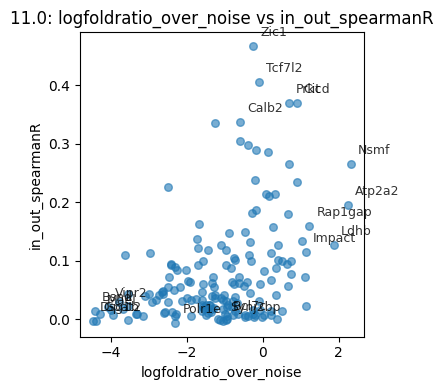

12.0


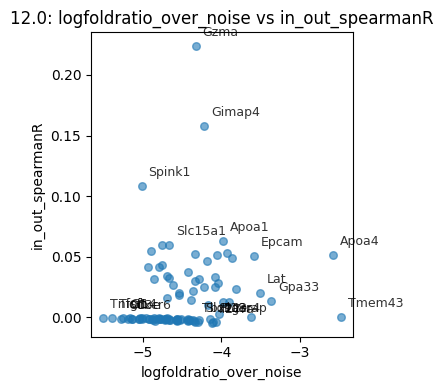

13.0


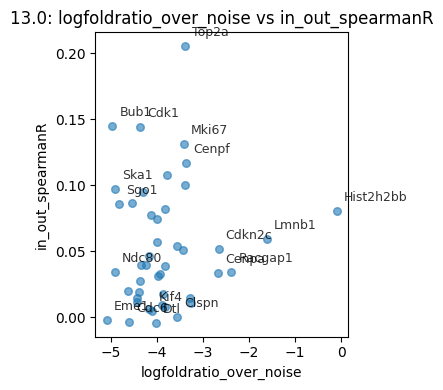

14.0


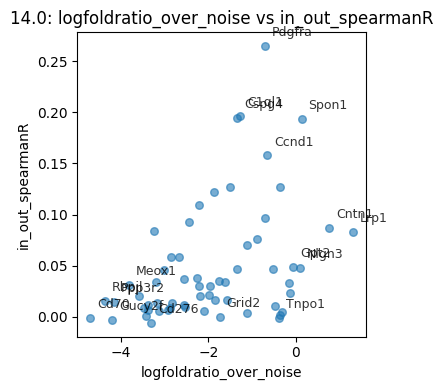

15.0


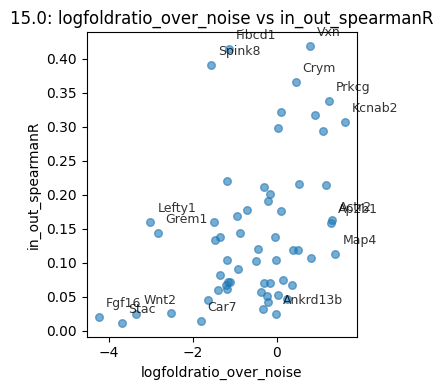

16.0


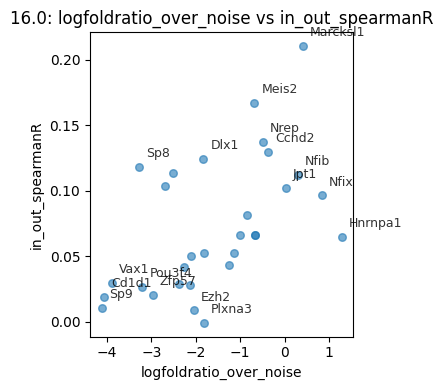

17.0


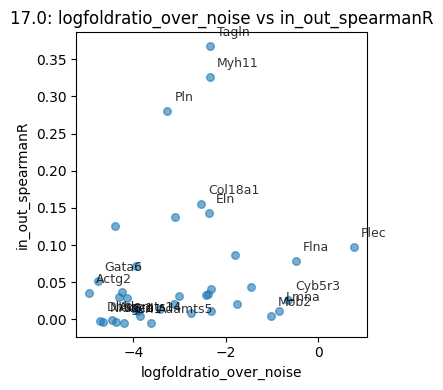

18.0


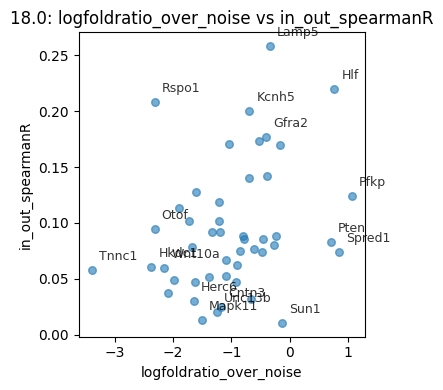

19.0


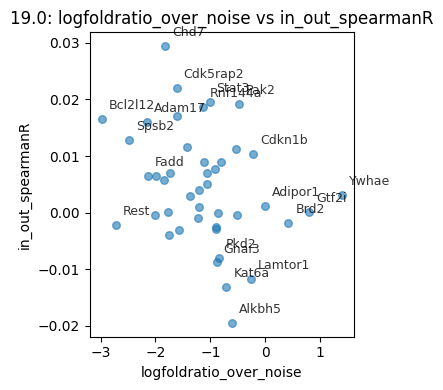

20.0


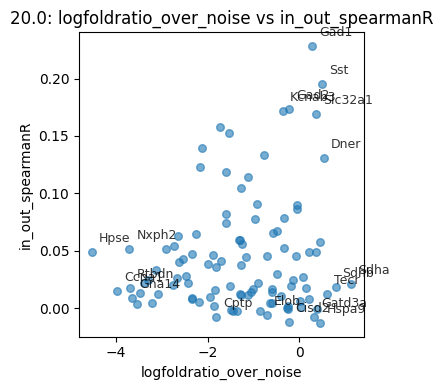

21.0


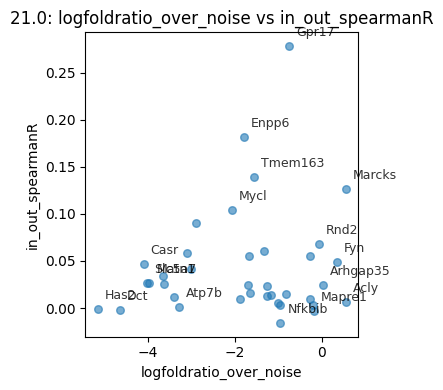

22.0


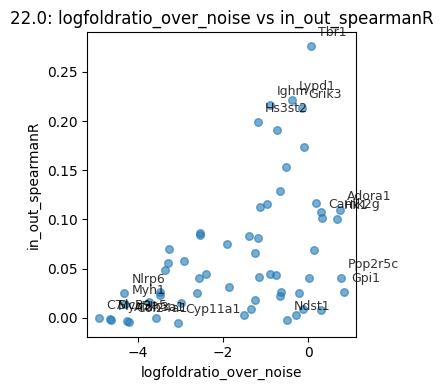

23.0


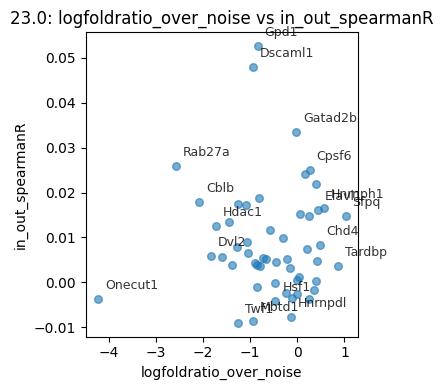

24.0


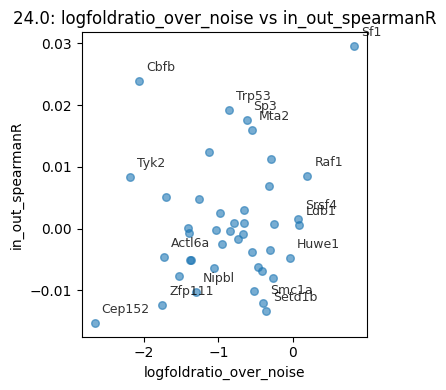

25.0


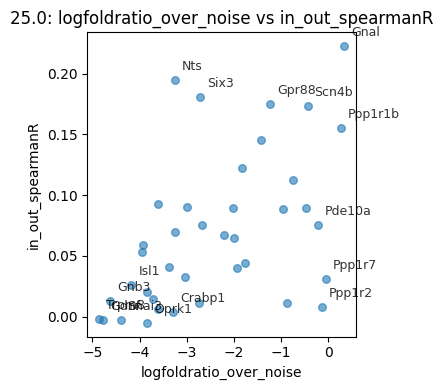

26.0


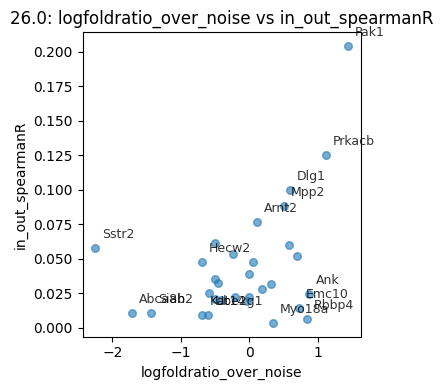

In [ ]:
for g, i in results.groupby("module"):
    if g > -1:
        print(g)
        # Suppose `results` is your DataFrame and you have a column 'gene' with names:
        fig, ax = annotate_top_bottom(
            df=i,
            metric1="logfoldratio_over_noise",
            metric2="in_out_spearmanR",
            n=5,
            scatter_kwargs={"alpha": 0.6, "s": 30},
            annotate_kwargs={"fontsize": 9, "color": "black"},
            title_tag=g,
            figsize=(3, 3),
        )
        plt.show()

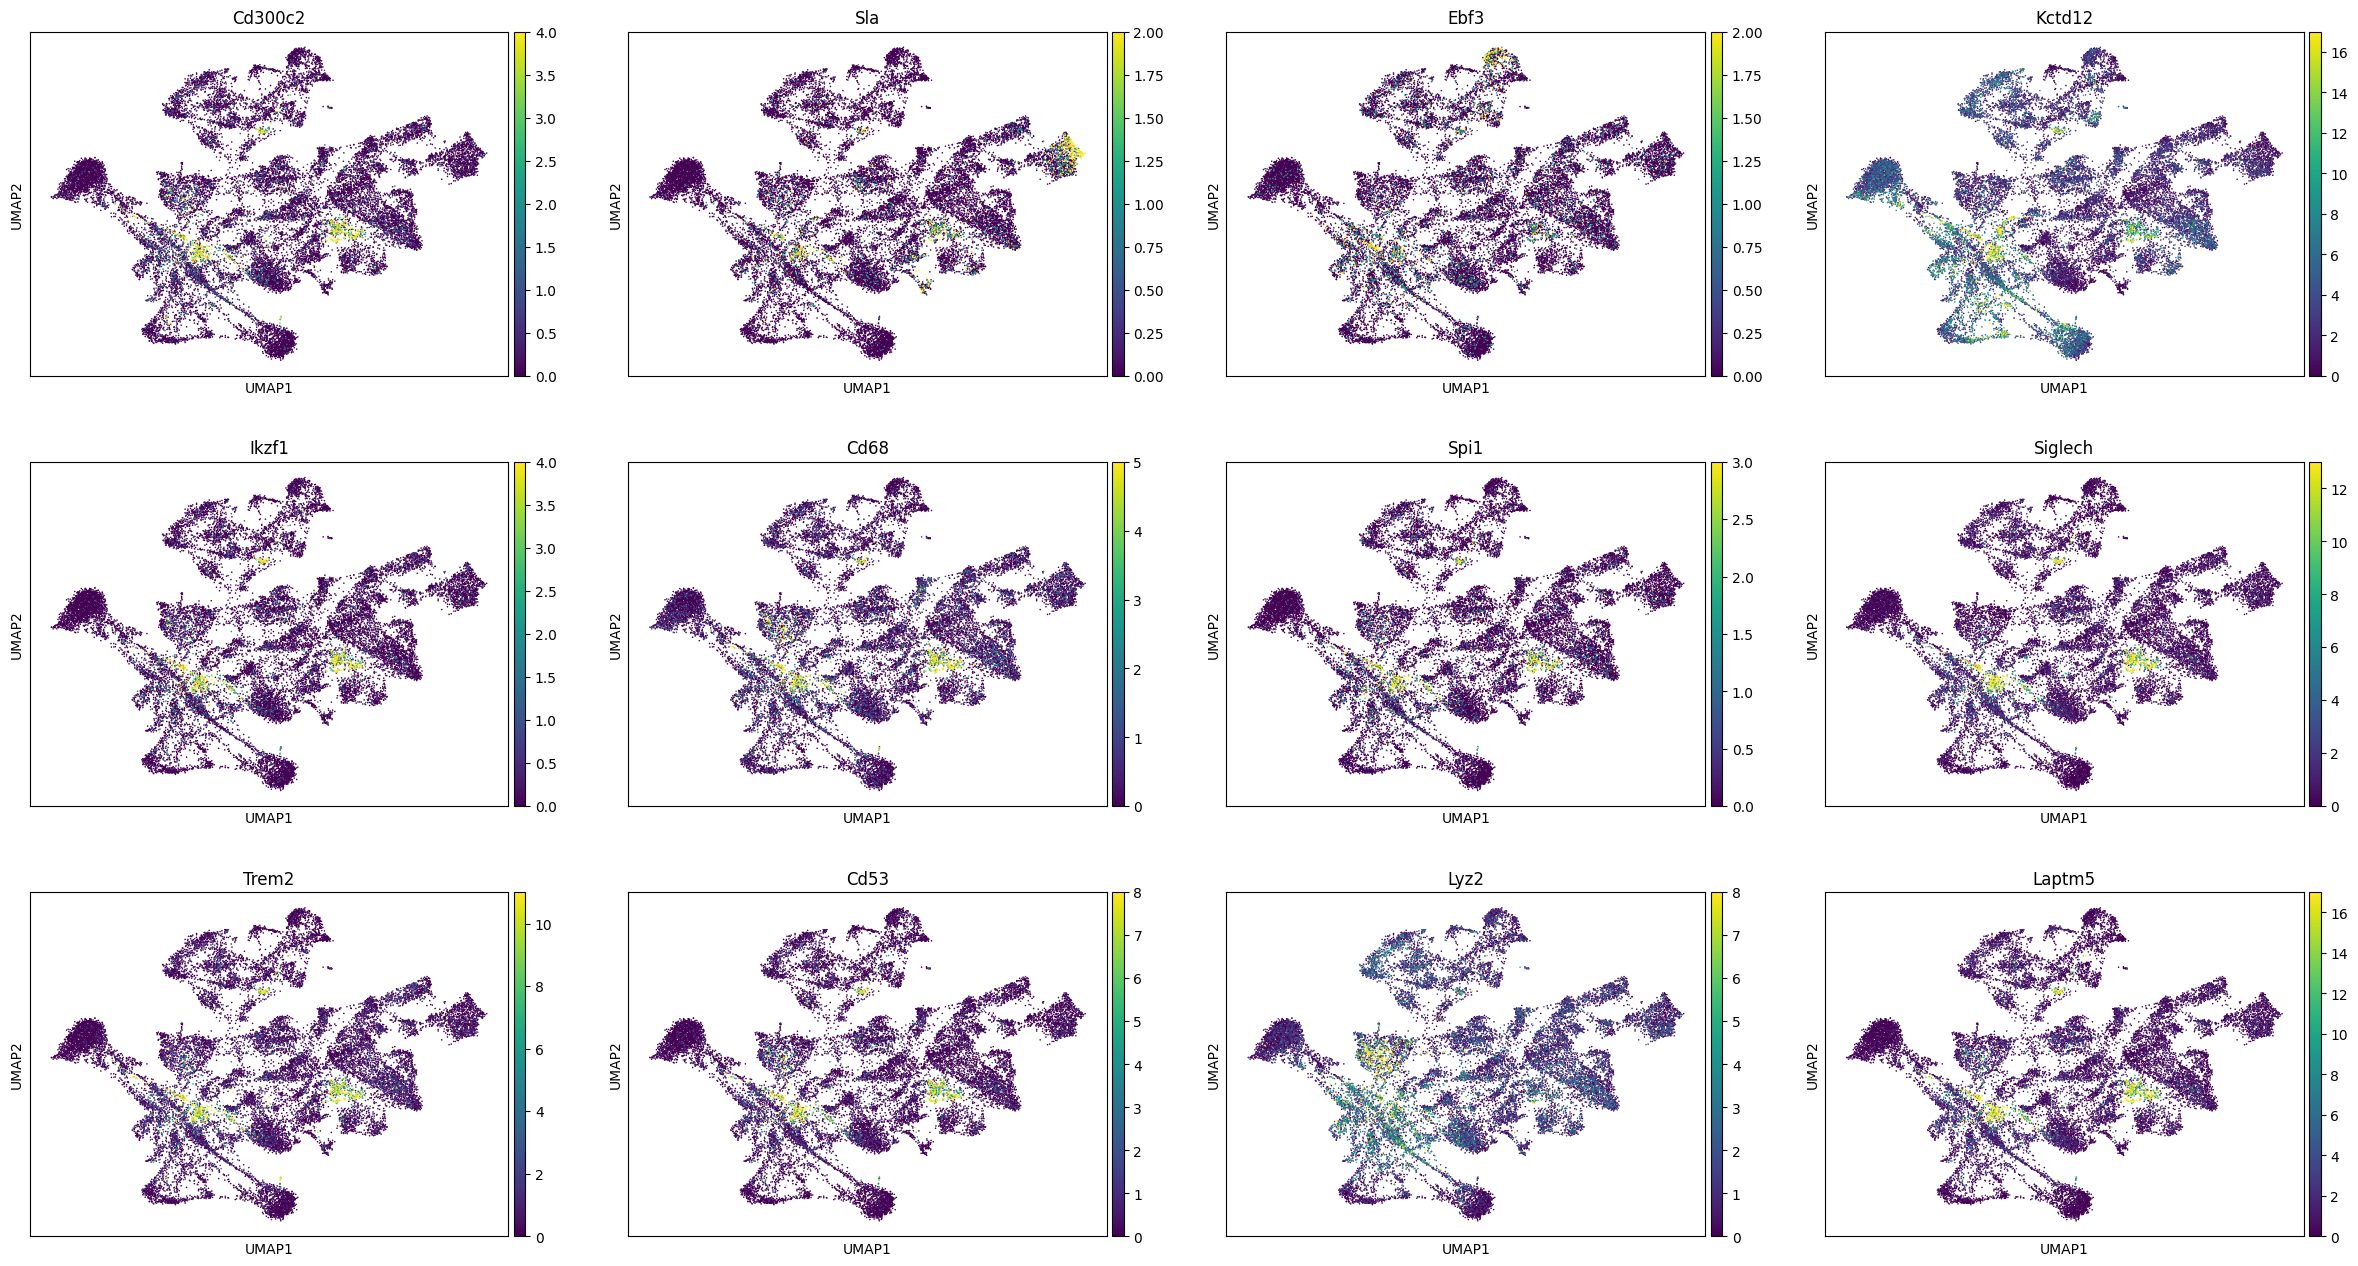

Index(['Cd300c2', 'Sla', 'Ebf3', 'Kctd12', 'Ikzf1', 'Cd68', 'Spi1', 'Siglech',
       'Trem2', 'Cd53', 'Lyz2', 'Laptm5'],
      dtype='object', name='gene_names')


In [98]:
mods_df = pd.DataFrame(modules).sort_values(by="Module")
genes = mods_df[mods_df["Module"] == 3].index
sc.pl.umap(adata, color=genes, vmax="p99")
print(genes)

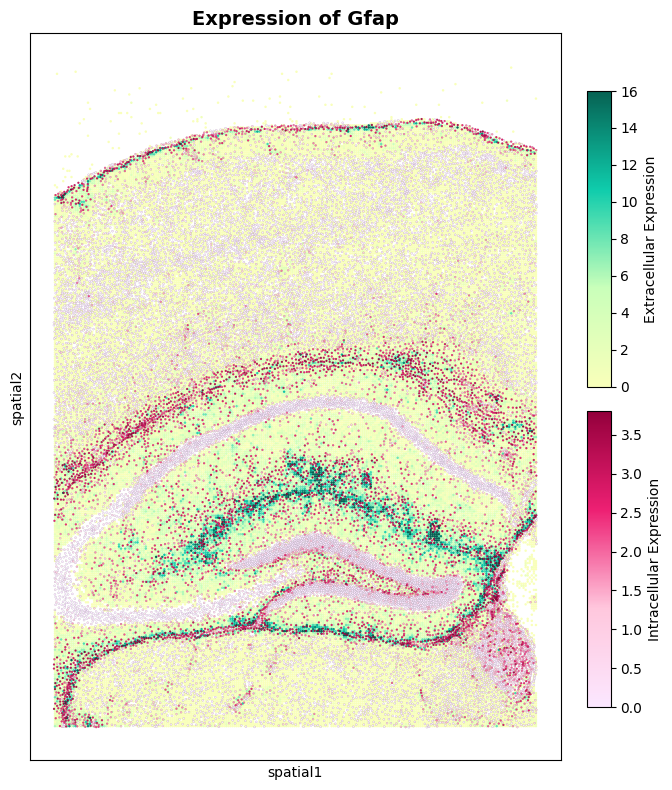

In [51]:
# spatial maps-in out
g2 = "Gfap"
troutpy.pl.spatial_inout_expression(sdata, g2, spot_size_cells=10)

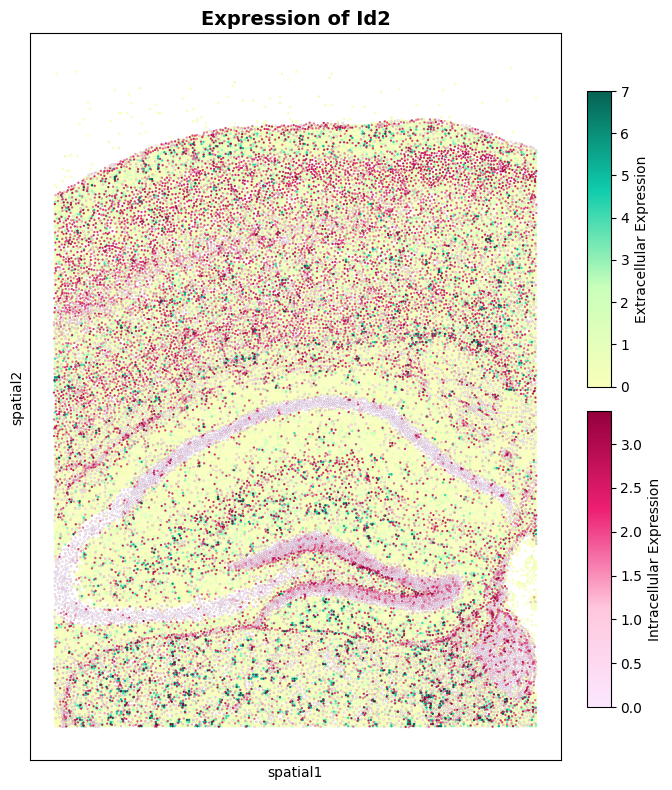

In [52]:
g2 = "Id2"
troutpy.pl.spatial_inout_expression(sdata, g2, spot_size_cells=10)

### Metrics by module

Text(0.5, 1.0, 'logfoldratio_over_noise')

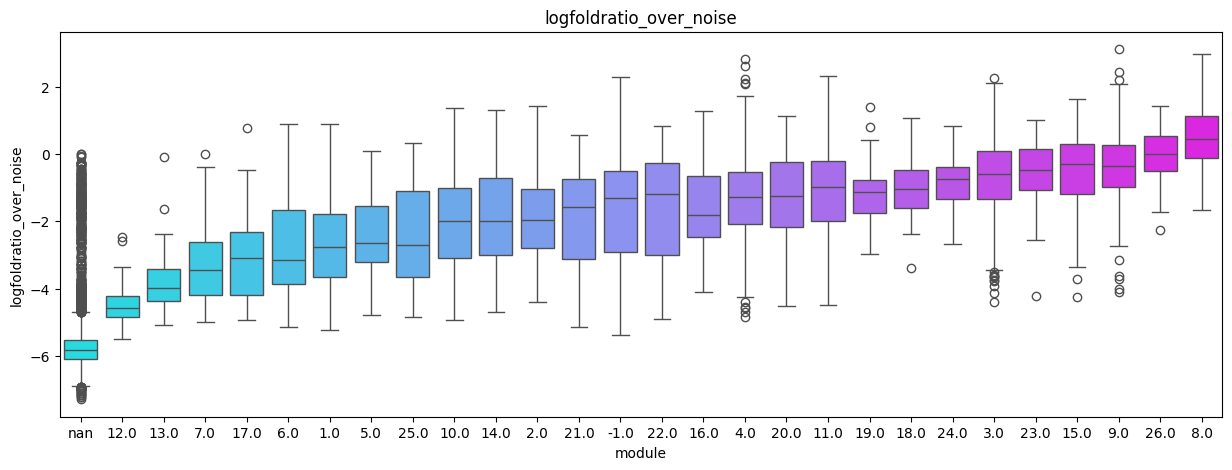

In [35]:
import seaborn as sns
import pandas as pd

variable = "logfoldratio_over_noise"

# Compute the mean logfoldratio_over_noise per module
order = results.groupby("module")[variable].mean().sort_values().index

# Convert 'module' to a categorical variable with the computed order
results["module"] = pd.Categorical(results["module"], categories=order, ordered=True)

plt.figure(figsize=(15, 5))
# Plot with sorted order
sns.boxplot(data=results, x="module", y=variable, hue="module", palette="cool", legend=False)
results["module"] = results["module"].astype(str)
plt.title(variable)

Text(0.5, 1.0, 'extracellular_proportion')

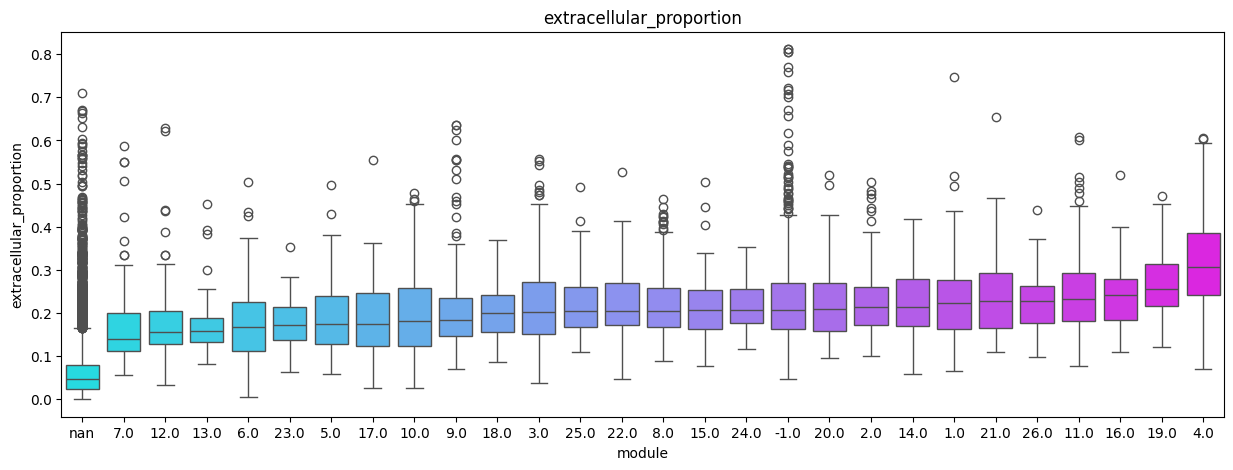

In [36]:
import seaborn as sns
import pandas as pd

variable = "extracellular_proportion"

# Compute the mean logfoldratio_over_noise per module
order = results.groupby("module")[variable].median().sort_values().index

# Convert 'module' to a categorical variable with the computed order
results["module"] = pd.Categorical(results["module"], categories=order, ordered=True)

plt.figure(figsize=(15, 5))
# Plot with sorted order
sns.boxplot(data=results, x="module", y=variable, hue="module", palette="cool", legend=False)
results["module"] = results["module"].astype(str)

plt.title(variable)

Text(0.5, 1.0, 'moran_I')

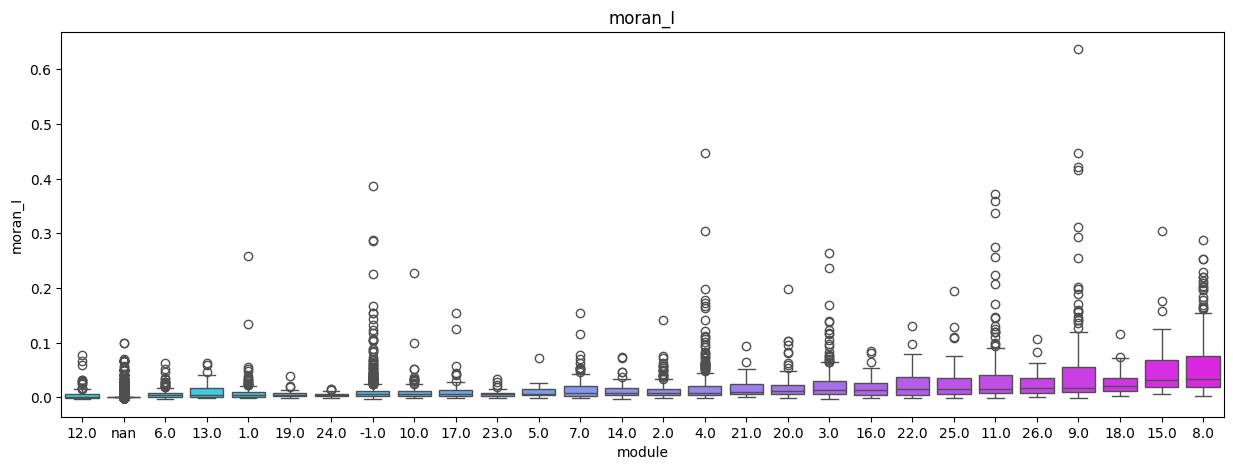

In [37]:
import seaborn as sns
import pandas as pd

variable = "moran_I"

# Compute the mean logfoldratio_over_noise per module
order = results.groupby("module")[variable].median().sort_values().index

# Convert 'module' to a categorical variable with the computed order
results["module"] = pd.Categorical(results["module"], categories=order, ordered=True)
plt.figure(figsize=(15, 5))
# Plot with sorted order
sns.boxplot(data=results, x="module", y=variable, hue="module", palette="cool", legend=False)
results["module"] = results["module"].astype(str)
plt.title(variable)